In [1]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.ensemble import RandomForestRegressor  # for regression
import os
import matplotlib.pyplot as plt

from statsmodels.tsa.ar_model import AutoReg
from statsmodels.tsa.stattools import adfuller
from sklearn.metrics import mean_squared_error
import matplotlib.dates as mdates

from sklearn.preprocessing import MinMaxScaler
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

from statsmodels.graphics.tsaplots import plot_acf
from statsmodels.stats.diagnostic import acorr_ljungbox


from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

from sklearn.model_selection import GridSearchCV, TimeSeriesSplit


import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import torch
import torch.nn as nn

from torch.utils.data import DataLoader, TensorDataset
from sklearn.ensemble import RandomForestRegressor
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score
from statsmodels.tsa.ar_model import AutoReg

In [2]:
df = pd.read_csv("offshore_windspeeds_NVE_areas.csv")

In [3]:
df

,value,year,time,name,lon,lat,row,col,locID
0,25.526188,1996,227904.0,Nordavind A,32.037722,71.120519,202,1072,1
1,25.729977,1996,227905.0,Nordavind A,32.037722,71.120519,202,1072,1
2,23.679323,1996,227906.0,Nordavind A,32.037722,71.120519,202,1072,1
3,25.401682,1996,227907.0,Nordavind A,32.037722,71.120519,202,1072,1
4,23.246597,1996,227908.0,Nordavind A,32.037722,71.120519,202,1072,1
...,...,...,...,...,...,...,...,...,...
4207675,14.840706,2019,438283.0,Vestavind B,3.751486,61.095909,256,519,9
4207676,15.772715,2019,438284.0,Vestavind B,3.751486,61.095909,256,519,9
4207677,16.767334,2019,438285.0,Vestavind B,3.751486,61.095909,256,519,9
4207678,16.755661,2019,438286.0,Vestavind B,3.751486,61.095909,256,519,9


In [4]:
df_Nordavind = df[(df["locID"] == 1) | (df["locID"] == 2) | (df["locID"] == 3) | (df["locID"] == 4)| (df["locID"] == 5) | (df["locID"] == 6)| (df["locID"] == 7)].copy()

In [5]:
df_Nordavind

,value,year,time,name,lon,lat,row,col,locID
0,25.526188,1996,227904.0,Nordavind A,32.037722,71.120519,202,1072,1
1,25.729977,1996,227905.0,Nordavind A,32.037722,71.120519,202,1072,1
2,23.679323,1996,227906.0,Nordavind A,32.037722,71.120519,202,1072,1
3,25.401682,1996,227907.0,Nordavind A,32.037722,71.120519,202,1072,1
4,23.246597,1996,227908.0,Nordavind A,32.037722,71.120519,202,1072,1
...,...,...,...,...,...,...,...,...,...
3786907,20.704819,2019,438283.0,Nordvest C,6.787949,63.804873,225,628,7
3786908,22.834248,2019,438284.0,Nordvest C,6.787949,63.804873,225,628,7
3786909,23.474638,2019,438285.0,Nordvest C,6.787949,63.804873,225,628,7
3786910,22.531391,2019,438286.0,Nordvest C,6.787949,63.804873,225,628,7


In [6]:
def remove_leap_day(df):

    df = df.copy()

    #df["datetime"] = pd.to_datetime(df["datetime"])

    df = df.loc[
        ~(
            (df["datetime"].dt.month == 2) &
            (df["datetime"].dt.day == 29)
        )
    ].reset_index(drop=True)

    return df

start_datetime = pd.Timestamp('1996-01-01 00:00:00')
start_time_value = df_Nordavind['time'].min()
df_Nordavind['datetime'] = start_datetime + pd.to_timedelta(df_Nordavind['time'] - start_time_value, unit='h')



# Lager kolonner for dato, måned og dag ---
df_Nordavind["date"] = df_Nordavind["datetime"].dt.date
df_Nordavind["month"] = df_Nordavind["datetime"].dt.month
df_Nordavind["day"] = df_Nordavind["datetime"].dt.day

df_Nordavind = remove_leap_day(df_Nordavind)

In [7]:
# Sørg for at datetime er riktig format
df_Nordavind["datetime"] = pd.to_datetime(
    df_Nordavind["datetime"]
).dt.round("h")

# Sorter etter lokasjon og tid
df_Nordavind = df_Nordavind.sort_values(
    ["locID", "datetime"]
)

# Funksjon for å beregne gjennomsnitt
def aggregate_wind(df, freq):
    return (
        df.set_index("datetime")
        .groupby("locID")
        .resample(freq)["value"]
        .mean()
        .reset_index()
    )

# Ulike tidsoppløsninger
df_Nordavind_3h = aggregate_wind(df_Nordavind, "3h")
df_Nordavind_6h = aggregate_wind(df_Nordavind, "6h")
df_Nordavind_12h = aggregate_wind(df_Nordavind, "12h")
df_Nordavind_daily = aggregate_wind(df_Nordavind, "1D")

In [8]:
df_Nordavind_3h

,locID,datetime,value
0,1,1996-01-01 00:00:00,24.978496
1,1,1996-01-01 03:00:00,24.197471
2,1,1996-01-01 06:00:00,24.593582
3,1,1996-01-01 09:00:00,28.994197
4,1,1996-01-01 12:00:00,31.685537
...,...,...,...
490891,7,2019-12-31 09:00:00,15.578020
490892,7,2019-12-31 12:00:00,18.715321
490893,7,2019-12-31 15:00:00,18.123505
490894,7,2019-12-31 18:00:00,20.919680


In [9]:
def pivot_wind(df):
    df_pivot = df.pivot(
        index="datetime",
        columns="locID",
        values="value"
    )

    df_pivot = df_pivot.rename(columns={
        1: "Nordavind_A",
        2: "Nordavind_B",
        3: "Nordavind_C",
        4: "Nordavind_D",
        5: "Nordvest_A",
        6: "Nordvest_B",
        7: "Nordvest_C"
    })

    return df_pivot.reset_index()

In [10]:
df_Nordavind_3h = pivot_wind(df_Nordavind_3h)

df_Nordavind_6h = pivot_wind(df_Nordavind_6h)

df_Nordavind_12h= pivot_wind(df_Nordavind_12h)

df_Nordavind_daily = pivot_wind(df_Nordavind_daily)

In [11]:
df_Nordavind_3h = remove_leap_day(df_Nordavind_3h)
df_Nordavind_6h = remove_leap_day(df_Nordavind_6h)
df_Nordavind_12h = remove_leap_day(df_Nordavind_12h)
df_Nordavind_daily = remove_leap_day(df_Nordavind_daily)

In [12]:
torch.manual_seed(42)
np.random.seed(42)

locations = [
    "Nordavind_A",
    "Nordavind_B",
    "Nordavind_C",
    "Nordavind_D",
    "Nordvest_A",
    "Nordvest_B",
    "Nordvest_C"
]

target_location = "Nordavind_A"

datasets = {
    "3 timer": (df_Nordavind_3h, 56, 8),
    "6 timer": (df_Nordavind_6h, 28, 4),
    "12 timer": (df_Nordavind_12h, 14, 2),
    "Daglig": (df_Nordavind_daily, 7, 1),
    "Daglig sesongjustert": (df_Nordavind_daily, 7, 1)
}

rf_params = dict(
    n_estimators=200,
    max_depth=20,
    min_samples_split=5,
    min_samples_leaf=2,
    max_features=0.7,
    random_state=42,
    n_jobs=-1
)

In [13]:
df_Nordavind_daily 

locID,datetime,Nordavind_A,Nordavind_B,Nordavind_C,Nordavind_D,Nordvest_A,Nordvest_B,Nordvest_C
0,1996-01-01,27.466171,26.796846,20.552794,22.425339,12.737762,8.179760,2.676077
1,1996-01-02,22.795527,18.476906,9.932294,8.240553,4.390807,2.973565,3.995115
2,1996-01-03,9.255732,8.806174,7.572234,8.477059,13.644229,12.470250,11.055423
3,1996-01-04,13.591242,13.888944,13.521795,12.302124,17.294898,17.563966,17.025294
4,1996-01-05,12.153363,8.704813,5.226901,6.463870,9.246001,8.113559,5.200689
...,...,...,...,...,...,...,...,...
8755,2019-12-27,6.869742,8.597234,10.915432,10.586806,10.282457,9.523757,9.121968
8756,2019-12-28,13.411871,15.654217,18.961049,19.585891,21.558617,23.639049,24.192228
8757,2019-12-29,16.787167,16.494733,14.408817,13.750938,16.950894,21.015834,22.617186
8758,2019-12-30,13.900942,12.757215,8.345718,8.431253,15.653378,19.608809,19.055815


In [14]:
def normalize_data(df):
    df = df.copy()

    if "datetime" not in df.columns:
        df = df.reset_index()

    df["datetime"] = pd.to_datetime(df["datetime"])

    df = df[["datetime"] + locations]
    df = df.sort_values("datetime")
    df = df.drop_duplicates(subset="datetime")

    # Fjern 29. februar
    leap = (
        (df["datetime"].dt.month == 2) &
        (df["datetime"].dt.day == 29)
    )
    df = df.loc[~leap].copy()

    df[locations] = df[locations].apply(
        pd.to_numeric, errors="coerce"
    )
    df[locations] = df[locations].replace(
        [np.inf, -np.inf], np.nan
    )

    if df[locations].isna().any().any():
        raise ValueError("Fortsatt NaN i vindobservasjonene.")

    return df.set_index("datetime").sort_index()


def season_features(index):
    index = pd.DatetimeIndex(index)

    day = index.dayofyear.to_numpy().astype(float)

    # Juster dagnummer etter 29. februar i skuddår
    after_feb = index.month > 2
    day -= (index.is_leap_year & after_feb).astype(int)

    # Ta også hensyn til klokkeslett
    fraction = (
        index.hour.to_numpy() / 24 +
        index.minute.to_numpy() / 1440
    )

    t = day - 1 + fraction

    return np.column_stack([
        np.ones(len(index)),
        np.cos(2 * np.pi * t / 365),
        np.sin(2 * np.pi * t / 365)
    ])


def fit_season(train_df, full_index):
    X_train = season_features(train_df.index)
    X_full = season_features(full_index)

    seasonal = pd.DataFrame(
        index=full_index,
        columns=locations,
        dtype=float
    )

    coefficients = {}

    for loc in locations:
        beta = np.linalg.lstsq(
            X_train,
            train_df[loc].to_numpy(),
            rcond=None
        )[0]

        seasonal[loc] = X_full @ beta
        coefficients[loc] = beta

    return seasonal, coefficients


def prepare_data(df, p, h, seasonal=False):
    original = normalize_data(df)

    # Split basert på kronologiske observasjoner
    split_raw = int(len(original) * 0.8)
    train_end = original.index[split_raw]

    if seasonal:
        season, coefficients = fit_season(
            original.iloc[:split_raw],
            original.index
        )
        working = original - season
    else:
        season = pd.DataFrame(
            0.0, index=original.index, columns=locations
        )
        coefficients = {}
        working = original.copy()

    lag_data = {}

    for lag in range(p):
        for loc in locations:
            lag_data[f"lag_{lag}_{loc}"] = (
                working[loc].shift(lag)
            )

    data = pd.DataFrame(lag_data, index=working.index)

    data["target"] = working[target_location].shift(-h)
    
    data["target_datetime"] = pd.Series(
        working.index, index=working.index
    ).shift(-h)

    lag_cols = [
        f"lag_{lag}_{loc}"
        for lag in range(p)
        for loc in locations
    ]

    # Kontroller faktiske tidsavstander
    step = pd.Timedelta(hours=24 / h)

    target_ok = (
        data["target_datetime"] - data.index == 
        pd.Timedelta(hours=24)
    )

    history_ok = pd.Series(True, index=working.index)

    for lag in range(1, p):
        history_ok &= (
            working.index.to_series() -
            working.index.to_series().shift(lag)
            == lag * step
        )

    data = data.loc[target_ok & history_ok].dropna(
        subset=lag_cols + ["target", "target_datetime"]
    )

    data["target_season"] = season[target_location].reindex(
        pd.to_datetime(data["target_datetime"])
    ).to_numpy()

    data["actual"] = (
        data["target"] + data["target_season"]
    )

    train = data.loc[data.index < train_end].copy()
    test = data.loc[data.index >= train_end].copy()

    return {
        "original": original,
        "working": working,
        "season": season,
        "coefficients": coefficients,
        "data": data,
        "train": train,
        "test": test,
        "lag_cols": lag_cols,
        "train_end": train_end
    }

In [15]:
def train_rf(prepared):

    train = prepared["train"]
    test = prepared["test"]
    lag_cols = prepared["lag_cols"]

    model = RandomForestRegressor(**rf_params)

    model.fit(
        train[lag_cols],
        train["target"]
    )

    pred = model.predict(test[lag_cols])

    # Legg sesongkomponenten tilbake
    pred = pred + test["target_season"].to_numpy()

    return model, pred

In [16]:
def train_ar(prepared, p, h):

    working = prepared["working"]
    test = prepared["test"]
    train_end = prepared["train_end"]

    train_series = working.loc[
        working.index < train_end, locations
    ].copy()

    # Numerisk indeks for AutoReg
    train_series = train_series.reset_index(drop=True)

    # AR-modeller for B, C og D
    other_models = {}
    other_params = {}

    for loc in locations[1:]:
        result = AutoReg(
            train_series[loc],
            lags=p,
            trend="c",
            old_names=False
        ).fit()

        other_models[loc] = result
        other_params[loc] = np.asarray(result.params)

    # Eksterne lagvariabler for A
    # Lag alle eksterne lagvariabler samtidig
    exog_dict = {
        f"lag_{lag}_{loc}": train_series[loc].shift(lag)
        for lag in range(1, p + 1)
        for loc in locations[1:]
    }

    exog = pd.DataFrame(exog_dict)

    exog_cols = list(exog_dict.keys())

    # AutoReg ignorerer de første p radene ved estimering
    exog = exog.fillna(0.0)

    ar_a = AutoReg(
        train_series[target_location],
        lags=p,
        exog=exog[exog_cols],
        trend="c",
        old_names=False
    )

    ar_a_result = ar_a.fit()

    params_a = np.asarray(ar_a_result.params)

    c_a = params_a[0]
    phi_a = params_a[1:p + 1]
    beta_a = params_a[p + 1:]

    predictions = []

    for origin in test.index:

        history_df = working.loc[
            working.index <= origin, locations
        ].iloc[-p:]

        history = {
            loc: list(history_df[loc].to_numpy())
            for loc in locations
        }

        # Rekursiv prognose h steg
        for step in range(h):

            next_values = {}

            # Prognoser for B, C og D
            for loc in locations[1:]:
                params = other_params[loc]

                c = params[0]
                phi = params[1:]

                lag_values = np.array(
                    history[loc][-p:][::-1]
                )

                next_values[loc] = (
                    c + np.dot(phi, lag_values)
                )

            # Autoregressive lag for A
            lag_a = np.array(
                history[target_location][-p:][::-1]
            )

            # Eksterne lag fra B, C og D
            exog_values = np.array([
                history[loc][-lag]
                for lag in range(1, p + 1)
                for loc in locations[1:]
            ])

            next_values[target_location] = (
                c_a
                + np.dot(phi_a, lag_a)
                + np.dot(beta_a, exog_values)
            )

            # Oppdater alle fire seriene samtidig
            for loc in locations:
                history[loc].append(next_values[loc])

        predictions.append(
            history[target_location][-1]
        )

    predictions = np.asarray(predictions)

    # Legg sesongkomponenten tilbake
    predictions += test["target_season"].to_numpy()

    models = {
        "Nordavind_A_ARX": ar_a_result,
        "andre_lokasjoner": other_models
    }

    return models, predictions

In [17]:
class WindANN(nn.Module):

    def __init__(self, input_size):
        super().__init__()

        self.network = nn.Sequential(
            nn.Linear(input_size, 64),
            nn.ReLU(),
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Linear(32, 1)
        )

    def forward(self, x):
        return self.network(x)


def train_ann(prepared, epochs=100, patience=10):

    train = prepared["train"]
    test = prepared["test"]
    lag_cols = prepared["lag_cols"]

    # Kronologisk valideringssplit
    split_val = int(len(train) * 0.9)

    train_fit = train.iloc[:split_val]
    validation = train.iloc[split_val:]

    X_train = train_fit[lag_cols].to_numpy()
    y_train = train_fit["target"].to_numpy().reshape(-1, 1)

    X_val = validation[lag_cols].to_numpy()
    y_val = validation["target"].to_numpy().reshape(-1, 1)

    X_test = test[lag_cols].to_numpy()

    scaler_X = MinMaxScaler()
    scaler_y = MinMaxScaler()

    X_train = scaler_X.fit_transform(X_train)
    X_val = scaler_X.transform(X_val)
    X_test = scaler_X.transform(X_test)

    y_train = scaler_y.fit_transform(y_train)
    y_val = scaler_y.transform(y_val)

    X_train = torch.tensor(X_train, dtype=torch.float32)
    y_train = torch.tensor(y_train, dtype=torch.float32)

    X_val = torch.tensor(X_val, dtype=torch.float32)
    y_val = torch.tensor(y_val, dtype=torch.float32)

    X_test = torch.tensor(X_test, dtype=torch.float32)

    loader = DataLoader(
        TensorDataset(X_train, y_train),
        batch_size=32,
        shuffle=True
    )

    model = WindANN(len(lag_cols))

    criterion = nn.MSELoss()
    optimizer = torch.optim.Adam(
        model.parameters(),
        lr=0.001
    )

    best_loss = float("inf")
    best_state = None
    best_epoch = 0
    wait = 0

    train_losses = []
    val_losses = []

    for epoch in range(epochs):

        model.train()
        batch_losses = []

        for xb, yb in loader:
            optimizer.zero_grad()

            prediction = model(xb)
            loss = criterion(prediction, yb)

            loss.backward()
            optimizer.step()

            batch_losses.append(loss.item())

        model.eval()

        with torch.no_grad():
            val_pred = model(X_val)
            val_loss = criterion(val_pred, y_val).item()

        train_loss = np.mean(batch_losses)

        train_losses.append(train_loss)
        val_losses.append(val_loss)

        if val_loss < best_loss:
            best_loss = val_loss
            best_epoch = epoch + 1
            best_state = {
                k: v.detach().clone()
                for k, v in model.state_dict().items()
            }
            wait = 0
        else:
            wait += 1

        if wait >= patience:
            break

    model.load_state_dict(best_state)
    model.eval()

    with torch.no_grad():
        pred_scaled = model(X_test).numpy()

    pred = scaler_y.inverse_transform(
        pred_scaled
    ).ravel()

    # Legg sesongkomponenten tilbake
    pred += test["target_season"].to_numpy()

    training_info = {
        "train_loss": train_losses,
        "val_loss": val_losses,
        "best_epoch": best_epoch,
        "best_val_loss": best_loss,
        "scaler_X": scaler_X,
        "scaler_y": scaler_y
    }

    return model, pred, training_info

In [18]:
def train_benchmark(prepared):

    test = prepared["test"]

    # Historiske observasjoner fra Nordavind A
    lag_cols_a = [
        col for col in prepared["lag_cols"]
        if col.endswith("_Nordavind_A")
    ]

    # Persistens: siste kjente observasjon
    pred_persistence = (
        test["lag_0_Nordavind_A"].to_numpy()
    )

    # Historisk gjennomsnitt: siste 7 døgn
    pred_mean = (
        test[lag_cols_a].mean(axis=1).to_numpy()
    )

    # Sesongjustering
    season = prepared["season"]

    if prepared["coefficients"]:

        # Sesongkomponent på prognosetidspunktet
        target_season = test["target_season"].to_numpy()

        # Sesongkomponent på observasjonstidspunktet
        current_season = season.loc[
            test.index, target_location
        ].to_numpy()

        # Persistens i residualene + sesongprognose
        pred_persistence = (
            pred_persistence + target_season
        )

        # Gjennomsnitt av residualer + sesongprognose
        pred_mean = pred_mean + target_season

    return {
        "Persistens": pred_persistence,
        "Historisk gjennomsnitt": pred_mean
    }

In [19]:
results = []
predictions_all = {}
trained_models = {}
ann_training = {}
seasonal_coefficients = {}

for resolution, (df, p, h) in datasets.items():

    print(f"\n{'=' * 60}")
    print(f"Tidsoppløsning: {resolution}")
    print(f"Lag: {p} | Horisont: {h} steg")
    print("=" * 60)

    is_seasonal = resolution == "Daglig sesongjustert"

    prepared = prepare_data(
        df, p, h, seasonal=is_seasonal
    )

    test = prepared["test"]
    actual = test["actual"].to_numpy()

    dates = pd.DatetimeIndex(
        test["target_datetime"]
    )

    print("Trening:", len(prepared["train"]))
    print("Test:", len(test))
    print("Inngangsvariabler:", len(prepared["lag_cols"]))

    # Random Forest
    print("Trener Random Forest...")
    rf_model, pred_rf = train_rf(prepared)

    # AutoReg
    print("Trener AutoReg...")
    ar_model, pred_ar = train_ar(prepared, p, h)

    # ANN
    print("Trener ANN...")
    ann_model, pred_ann, ann_info = train_ann(prepared)
    
    print("Beregner benchmark...")
    benchmark_preds = train_benchmark(prepared)

    predictions_all[resolution] = pd.DataFrame({
    "datetime": dates,
    "Observert": actual,
    "Random Forest": pred_rf,
    "AutoReg": pred_ar,
    "ANN": pred_ann,
    "Persistens": benchmark_preds["Persistens"],
    "Historisk gjennomsnitt": benchmark_preds["Historisk gjennomsnitt"]
    })

    trained_models[resolution] = {
        "RF": rf_model,
        "AR": ar_model,
        "ANN": ann_model
    }

    ann_training[resolution] = ann_info

    seasonal_coefficients[resolution] = (
        prepared["coefficients"]
    )

    for name, pred in [
        ("Random Forest", pred_rf),
        ("AutoReg", pred_ar),
        ("ANN", pred_ann),
        ("Persistens", benchmark_preds["Persistens"]),
        ("Historisk gjennomsnitt", benchmark_preds["Historisk gjennomsnitt"])
    ]:

        mse = mean_squared_error(actual, pred)

        results.append({
            "Modell": name,
            "Tidsoppløsning": resolution,
            "MSE": mse,
            "RMSE": np.sqrt(mse),
            "MAE": mean_absolute_error(actual, pred),
            "R²": r2_score(actual, pred)
        })

results_df = pd.DataFrame(results)

order = list(datasets.keys())
results_df["Tidsoppløsning"] = pd.Categorical(
    results_df["Tidsoppløsning"],
    categories=order,
    ordered=True
)

results_df = results_df.sort_values(
    ["Tidsoppløsning", "RMSE"]
).reset_index(drop=True)

display(results_df.round(4))


Tidsoppløsning: 3 timer
Lag: 56 | Horisont: 8 steg
Trening: 55694
Test: 13945
Inngangsvariabler: 392
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: 6 timer
Lag: 28 | Horisont: 4 steg
Trening: 27850
Test: 6973
Inngangsvariabler: 196
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: 12 timer
Lag: 14 | Horisont: 2 steg
Trening: 13928
Test: 3487
Inngangsvariabler: 98
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: Daglig
Lag: 7 | Horisont: 1 steg
Trening: 6967
Test: 1744
Inngangsvariabler: 49
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...

Tidsoppløsning: Daglig sesongjustert
Lag: 7 | Horisont: 1 steg
Trening: 6967
Test: 1744
Inngangsvariabler: 49
Trener Random Forest...
Trener AutoReg...
Trener ANN...
Beregner benchmark...


,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²
0,Random Forest,3 timer,16.8854,4.1092,3.3145,0.1311
1,ANN,3 timer,17.1287,4.1387,3.3464,0.1186
2,AutoReg,3 timer,17.8729,4.2276,3.4124,0.0803
3,Historisk gjennomsnitt,3 timer,21.3754,4.6233,3.7262,-0.0999
4,Persistens,3 timer,29.7953,5.4585,4.3126,-0.5332
5,Random Forest,6 timer,15.8993,3.9874,3.2223,0.1443
6,ANN,6 timer,15.9810,3.9976,3.2238,0.1400
7,AutoReg,6 timer,16.6870,4.0850,3.2966,0.1020
8,Historisk gjennomsnitt,6 timer,20.4390,4.5209,3.6426,-0.1000
9,Persistens,6 timer,27.9781,5.2894,4.1850,-0.5057


In [20]:
results_df.to_csv(
    "samlet_modellsammenligning_loc1_6.csv",
    index=False
)

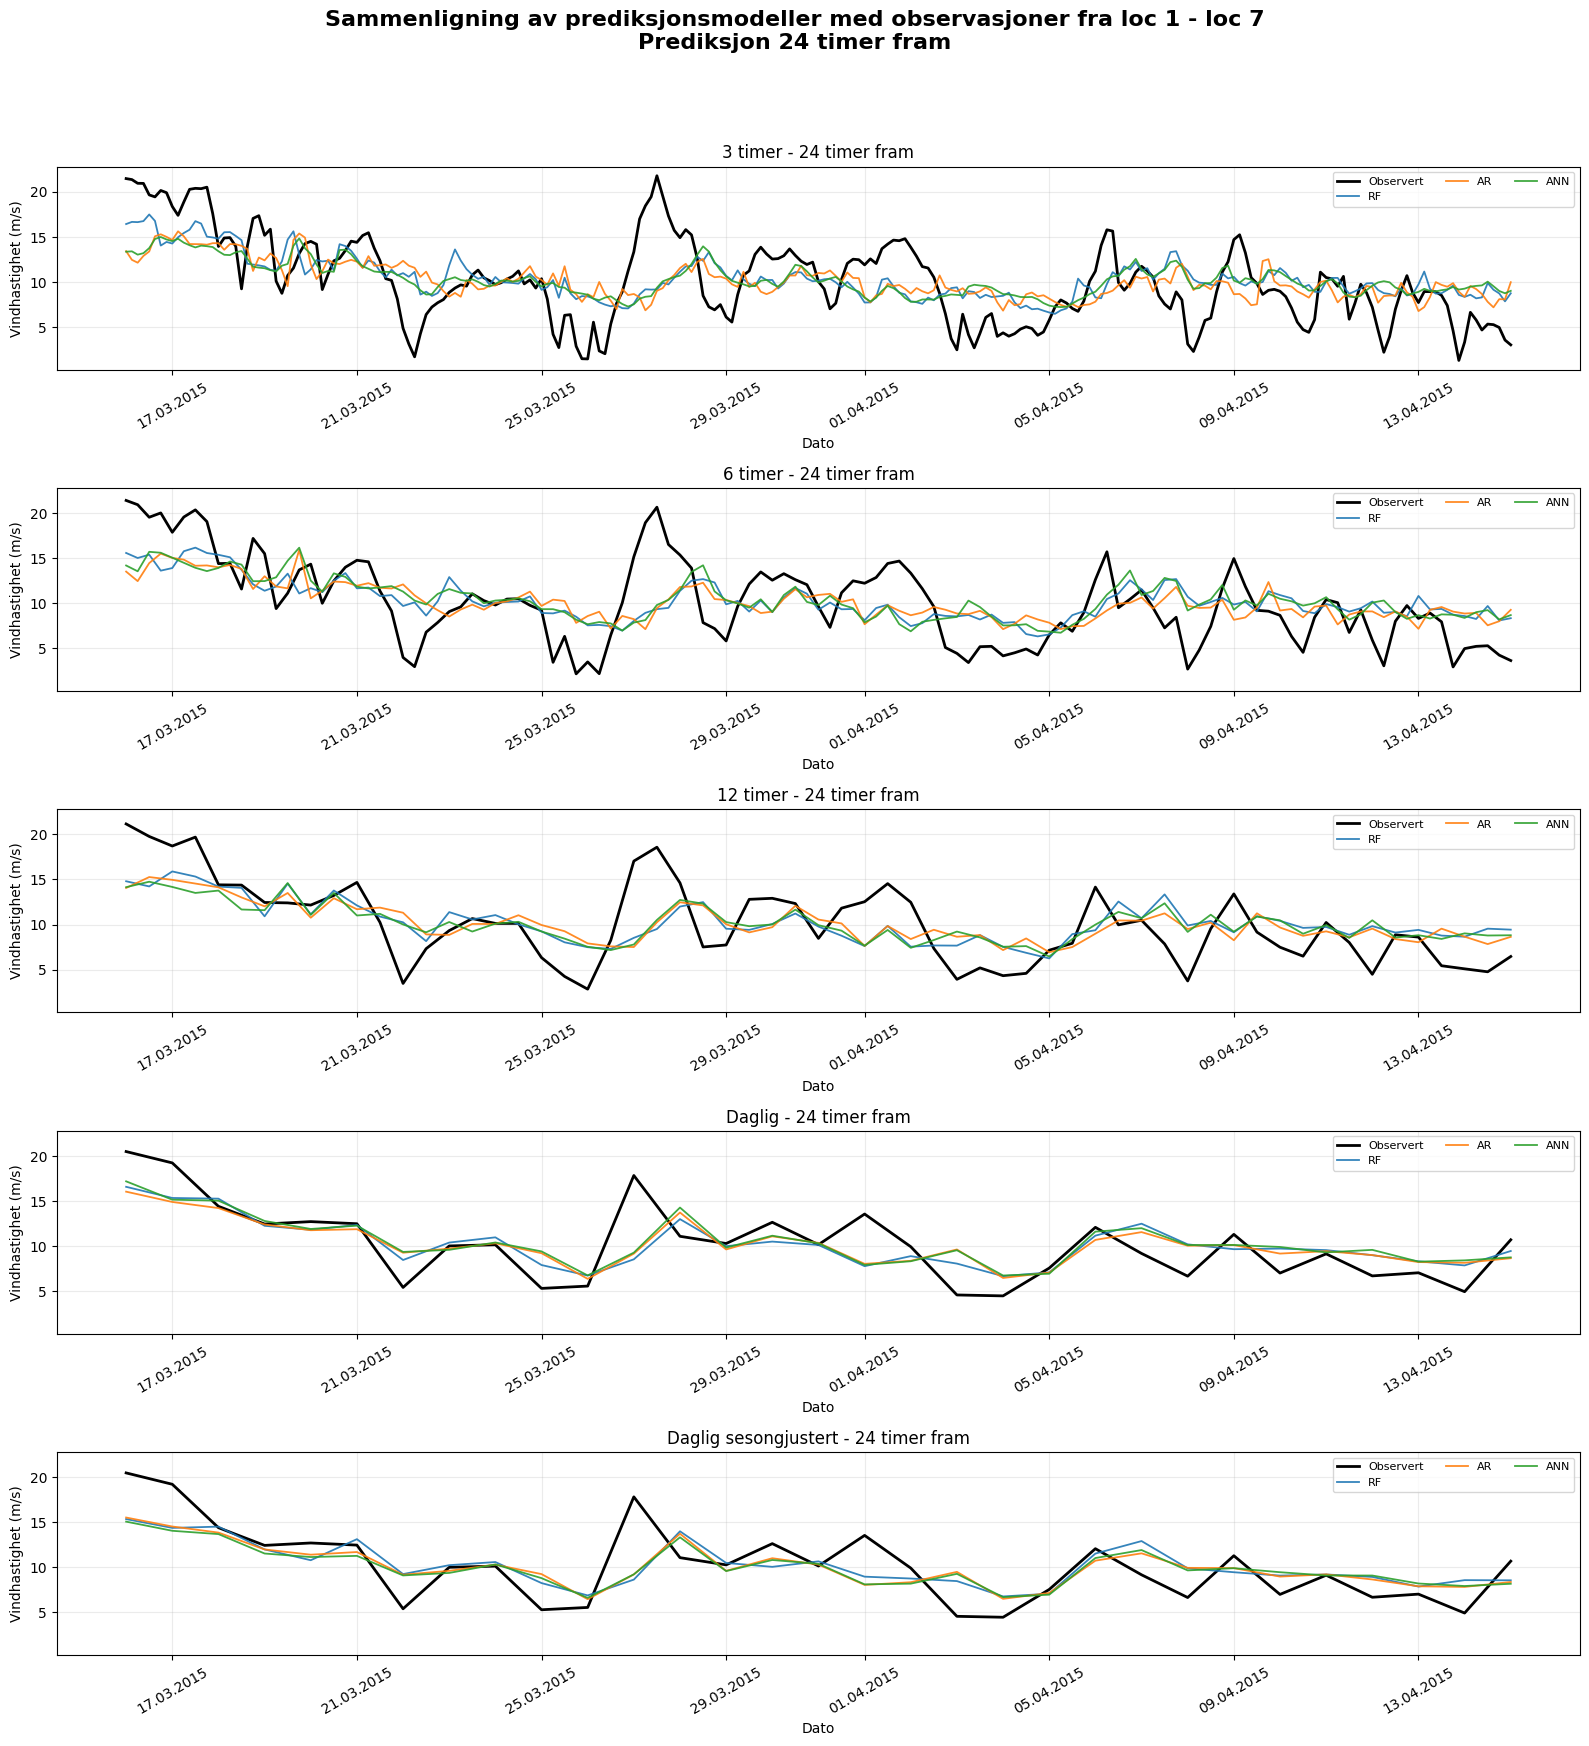

In [21]:


# Modellnavn og farger
models = {
    "Observert": "black",
    "Random Forest": "tab:blue",
    "AutoReg": "tab:orange",
    "ANN": "tab:green",
 #   "Persistens": "tab:red",
 #   "Ukesgjennomsnitt": "tab:purple"
}

# Kortere navn i tegnforklaringen
labels = {
    "Observert": "Observert",
    "Random Forest": "RF",
    "AutoReg": "AR",
    "ANN": "ANN",
#    "Persistens": "Persistens",
#    "Ukesgjennomsnitt": "Ukesgjennomsnitt"
}

n_plots = len(predictions_all)

fig, axes = plt.subplots(
    n_plots, 1,
    figsize=(16, 3.5 * n_plots),
    sharey=True
)

if n_plots == 1:
    axes = [axes]

for ax, (resolution, df_plot) in zip(
    axes, predictions_all.items()
):

    # Første 30 dager i testperioden
    start = df_plot["datetime"].min()
    end = start + pd.Timedelta(days=30)

    plot_data = df_plot.loc[
        (df_plot["datetime"] >= start) &
        (df_plot["datetime"] <= end)
    ].sort_values("datetime")

    # Plott alle modellene
    for name, color in models.items():

        if name not in plot_data.columns:
            continue

        ax.plot(
            plot_data["datetime"],
            plot_data[name],
            label=labels[name],
            color=color,
            linewidth=2 if name == "Observert" else 1.3,
            alpha=1 if name == "Observert" else 0.9
        )

    ax.set_title(
        f"{resolution} - 24 timer fram",
        fontsize=12
    )

    ax.set_ylabel("Vindhastighet (m/s)")
    ax.set_xlabel("Dato")

    ax.grid(alpha=0.25)

    # Datoformat
    ax.xaxis.set_major_formatter(
        mdates.DateFormatter("%d.%m.%Y")
    )

    ax.xaxis.set_major_locator(
        mdates.AutoDateLocator()
    )

    ax.tick_params(axis="x", rotation=30)

    # Tegnforklaring i hvert delplott
    ax.legend(
        loc="upper right",
        ncol=3,
        fontsize=8,
        frameon=True
    )

fig.suptitle(
    "Sammenligning av prediksjonsmodeller med observasjoner fra loc 1 - loc 7\n"
    "Prediksjon 24 timer fram",
    fontsize=16,
    fontweight="bold",
    y=0.995
)

plt.tight_layout(rect=[0, 0, 1, 0.96])

plt.savefig(
    "Sammenligning_24timer_Nordavind_A.pdf",
    bbox_inches="tight",
    dpi=300
)

plt.show()

Modell,ANN,AutoReg,Historisk gjennomsnitt,Persistens,Random Forest
Tidsoppløsning,,,,,
3 timer,4.1387,4.2276,4.6233,5.4585,4.1092
6 timer,3.9976,4.0850,4.5209,5.2894,3.9874
12 timer,3.7458,3.7930,4.2967,4.8993,3.7510
Daglig,3.1758,3.1534,3.7914,3.9129,3.1612
Daglig sesongjustert,3.1524,3.1548,3.7905,3.9129,3.1958


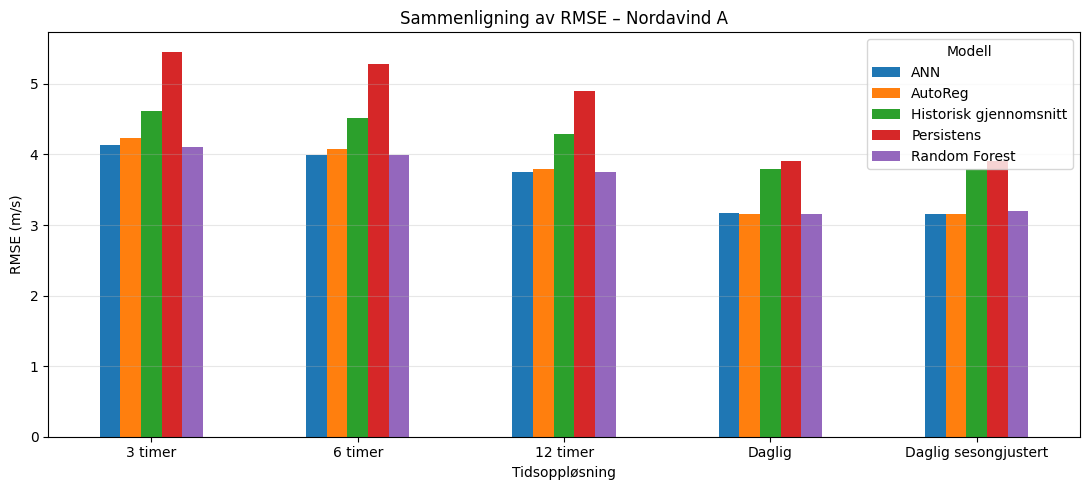


Beste modell:


,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²
20,ANN,Daglig sesongjustert,9.937654,3.152404,2.532988,0.262927


In [22]:
rmse_table = results_df.pivot(
    index="Tidsoppløsning",
    columns="Modell",
    values="RMSE"
)

display(rmse_table.round(4))

ax = rmse_table.plot(
    kind="bar",
    figsize=(11, 5),
    rot=0
)

ax.set_title("Sammenligning av RMSE – Nordavind A")
ax.set_ylabel("RMSE (m/s)")
ax.set_xlabel("Tidsoppløsning")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print("\nBeste modell:")
display(
    results_df.sort_values("RMSE").head(1)
)

In [23]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np

# Gamle resultater
results_loc_1 = pd.read_csv("samlet_modellsammenligning.csv")
results_loc_1_4 = pd.read_csv("samlet_modellsammenligning_loc1_4.csv")


# Nye resultater
results_loc_1_7 = results_df.copy()

# Legg til hvilken kjøring resultatene kommer fra
results_loc_1["Resultat"] = "Loc_1"
results_loc_1_4["Resultat"] = "Loc_1_4"
results_loc_1_7["Resultat"] = "Loc_1_7"

# Kombiner resultatene
results_comparison = pd.concat(
    [results_loc_1, results_loc_1_4, results_loc_1_7],
    ignore_index=True
)

display(results_comparison)

,Modell,Tidsoppløsning,MSE,RMSE,MAE,R²,Resultat
0,ANN,3 timer,18.235717,4.270330,3.468628,0.058726,Loc_1
1,AutoReg,3 timer,18.316880,4.279822,3.462388,0.056813,Loc_1
2,Historisk gjennomsnitt,3 timer,21.393334,4.625293,3.729365,-0.104261,Loc_1
3,Persistens,3 timer,29.696228,5.449425,4.304176,-0.532832,Loc_1
4,Random Forest,3 timer,18.117221,4.256433,3.436519,0.064842,Loc_1
...,...,...,...,...,...,...,...
70,ANN,Daglig sesongjustert,9.937654,3.152404,2.532988,0.262927,Loc_1_7
71,AutoReg,Daglig sesongjustert,9.952981,3.154835,2.536306,0.261791,Loc_1_7
72,Random Forest,Daglig sesongjustert,10.212978,3.195775,2.564827,0.242507,Loc_1_7
73,Historisk gjennomsnitt,Daglig sesongjustert,14.367737,3.790480,3.031703,-0.065650,Loc_1_7


In [24]:
rmse_comparison = results_comparison.pivot_table(
    index=["Tidsoppløsning", "Modell"],
    columns="Resultat",
    values="RMSE",
    aggfunc="first"
)

# Endring i RMSE
rmse_comparison["Endring"] = (
    rmse_comparison["Loc_1_7"] - rmse_comparison["Loc_1_4"]
)

# Prosentvis endring
rmse_comparison["Endring (%)"] = (
    rmse_comparison["Endring"]
    / rmse_comparison["Loc_1_4"] * 100
)

display(rmse_comparison.round(4))

Resultat                                      Loc_1  Loc_1_4  Loc_1_7  \
Tidsoppløsning       Modell                                             
12 timer             ANN                     3.9186   3.7700   3.7458   
                     AutoReg                 3.9300   3.8188   3.7930   
                     Historisk gjennomsnitt  4.3000   4.2967   4.2967   
                     Persistens              4.8913   4.8993   4.8993   
                     Random Forest           3.9462   3.7784   3.7510   
3 timer              ANN                     4.2703   4.1505   4.1387   
                     AutoReg                 4.2798   4.2406   4.2276   
                     Historisk gjennomsnitt  4.6253   4.6233   4.6233   
                     Persistens              5.4494   5.4585   5.4585   
                     Random Forest           4.2564   4.1291   4.1092   
6 timer              ANN                     4.1653   4.0208   3.9976   
                     AutoReg                 4.1719   4.1021   4.0850   
                     Historisk gjennomsnitt  4.5233   4.5209   4.5209   
                     Persistens              5.2808   5.2894   5.2894   
                     Random Forest           4.1594   4.0157   3.9874   
Daglig               ANN                     3.3073   3.1959   3.1758   
                     AutoReg                 3.3156   3.1759   3.1534   
                     Historisk gjennomsnitt  3.7964   3.7914   3.7914   
                     Persistens              3.9088   3.9129   3.9129   
                     Random Forest           3.3928   3.1970   3.1612   
Daglig sesongjustert ANN                     3.2964   3.1708   3.1524   
                     AutoReg                 3.2919   3.1650   3.1548   
                     Historisk gjennomsnitt  3.7957   3.7905   3.7905   
                     Persistens              3.9088   3.9129   3.9129   
                     Random Forest           3.3803   3.2135   3.1958   

Resultat                                     Endring  Endring (%)  
Tidsoppløsning       Modell                                        
12 timer             ANN                     -0.0241      -0.6398  
                     AutoReg                 -0.0258      -0.6757  
                     Historisk gjennomsnitt  -0.0000      -0.0000  
                     Persistens               0.0000       0.0000  
                     Random Forest           -0.0273      -0.7234  
3 timer              ANN                     -0.0118      -0.2850  
                     AutoReg                 -0.0130      -0.3058  
                     Historisk gjennomsnitt   0.0000       0.0000  
                     Persistens               0.0000       0.0000  
                     Random Forest           -0.0200      -0.4832  
6 timer              ANN                     -0.0232      -0.5771  
                     AutoReg                 -0.0171      -0.4167  
                     Historisk gjennomsnitt   0.0000       0.0000  
                     Persistens              -0.0000      -0.0000  
                     Random Forest           -0.0283      -0.7048  
Daglig               ANN                     -0.0201      -0.6283  
                     AutoReg                 -0.0225      -0.7081  
                     Historisk gjennomsnitt   0.0000       0.0000  
                     Persistens              -0.0000      -0.0000  
                     Random Forest           -0.0358      -1.1198  
Daglig sesongjustert ANN                     -0.0184      -0.5813  
                     AutoReg                 -0.0101      -0.3206  
                     Historisk gjennomsnitt   0.0000       0.0000  
                     Persistens               0.0000       0.0000  
                     Random Forest           -0.0177      -0.5509

In [25]:
coefficients = seasonal_coefficients[
    "Daglig sesongjustert"
]

season_table = pd.DataFrame(
    coefficients,
    index=["mu0", "mu1", "mu2"]
).T

season_table["Amplitude"] = np.sqrt(
    season_table["mu1"]**2 +
    season_table["mu2"]**2
)

display(season_table.round(4))

,mu0,mu1,mu2,Amplitude
Nordavind_A,9.4627,1.4697,0.1667,1.4791
Nordavind_B,9.5995,1.4798,0.2406,1.4993
Nordavind_C,9.5555,1.6323,0.3202,1.6634
Nordavind_D,9.5434,1.6694,0.2923,1.6948
Nordvest_A,9.8313,2.1256,0.2196,2.1369
Nordvest_B,9.7996,2.0807,0.2203,2.0923
Nordvest_C,9.7084,1.9447,0.2826,1.9651


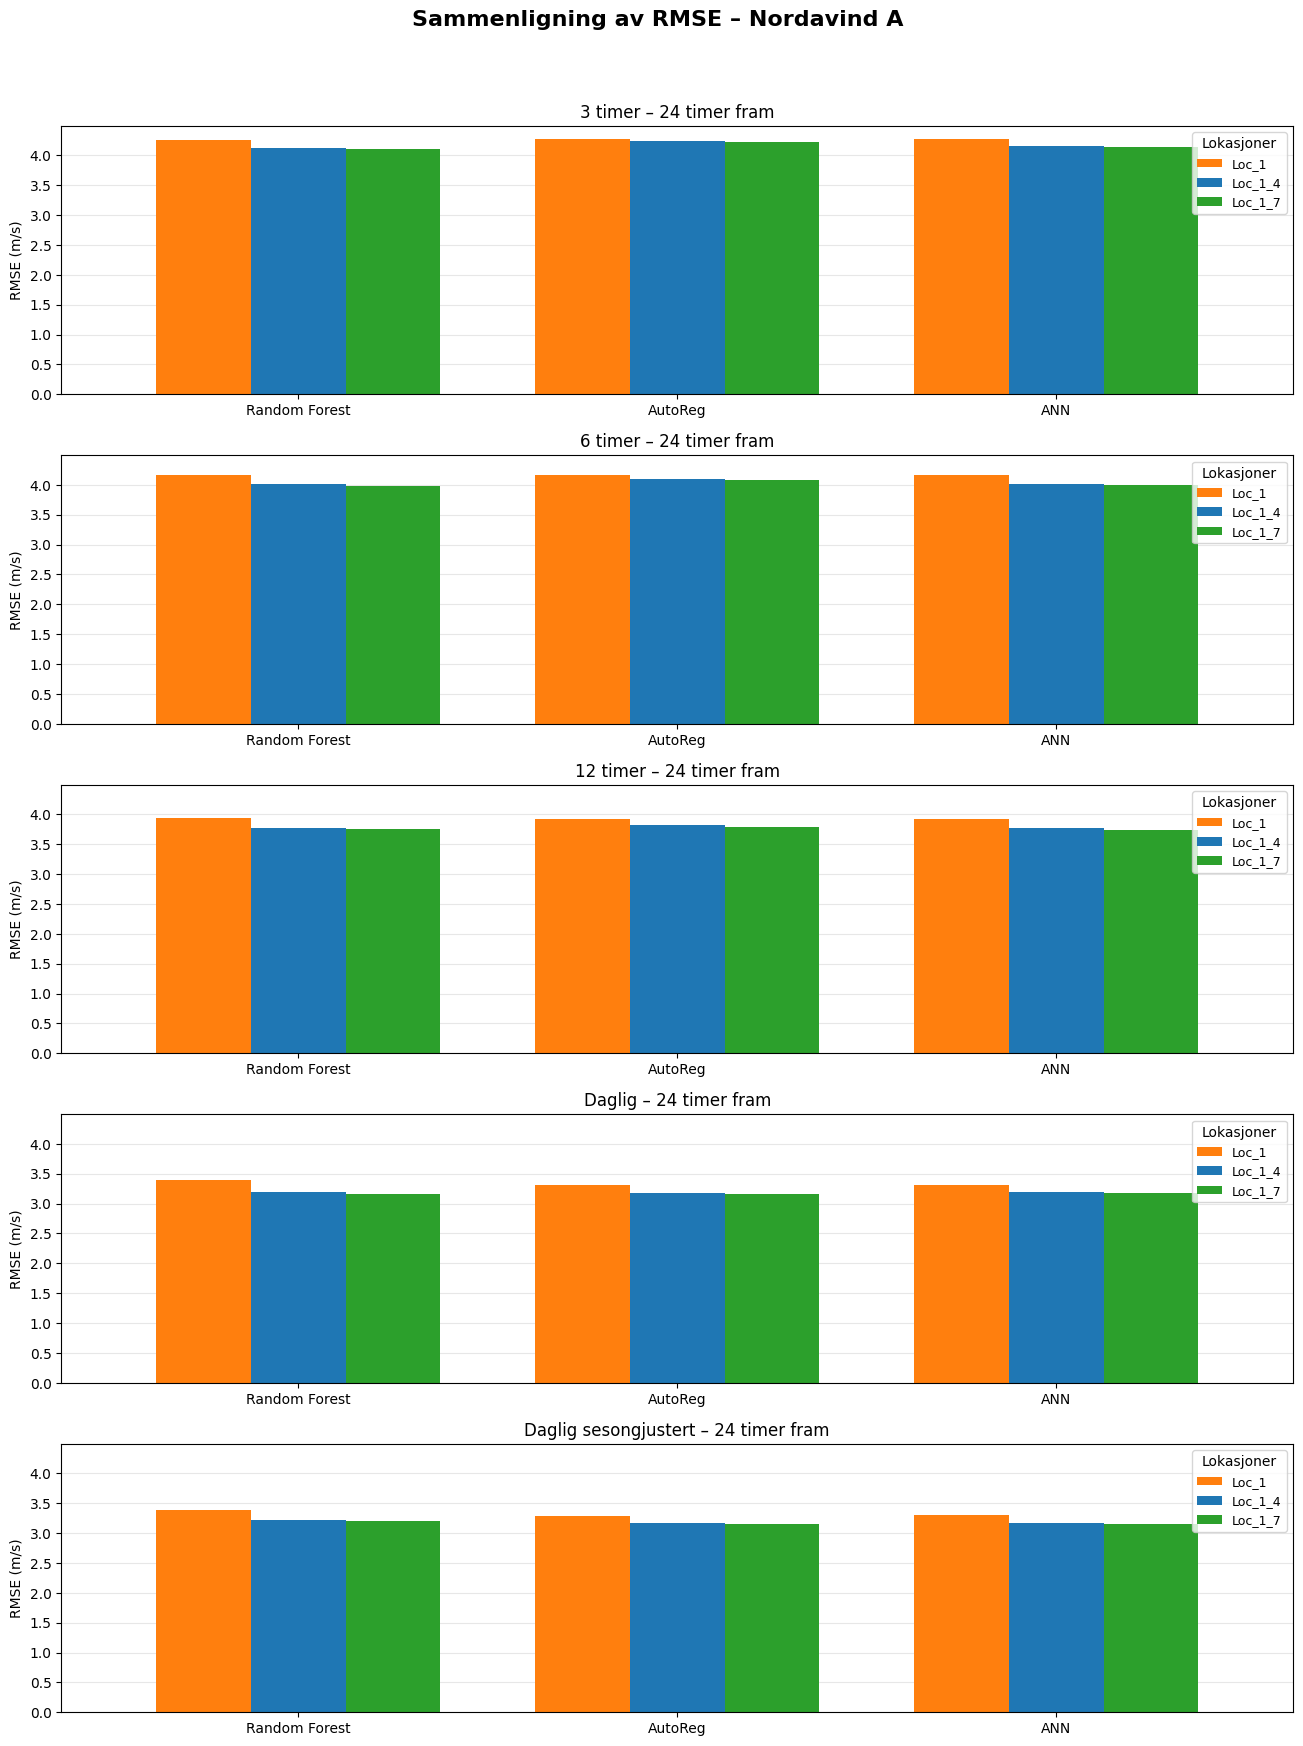

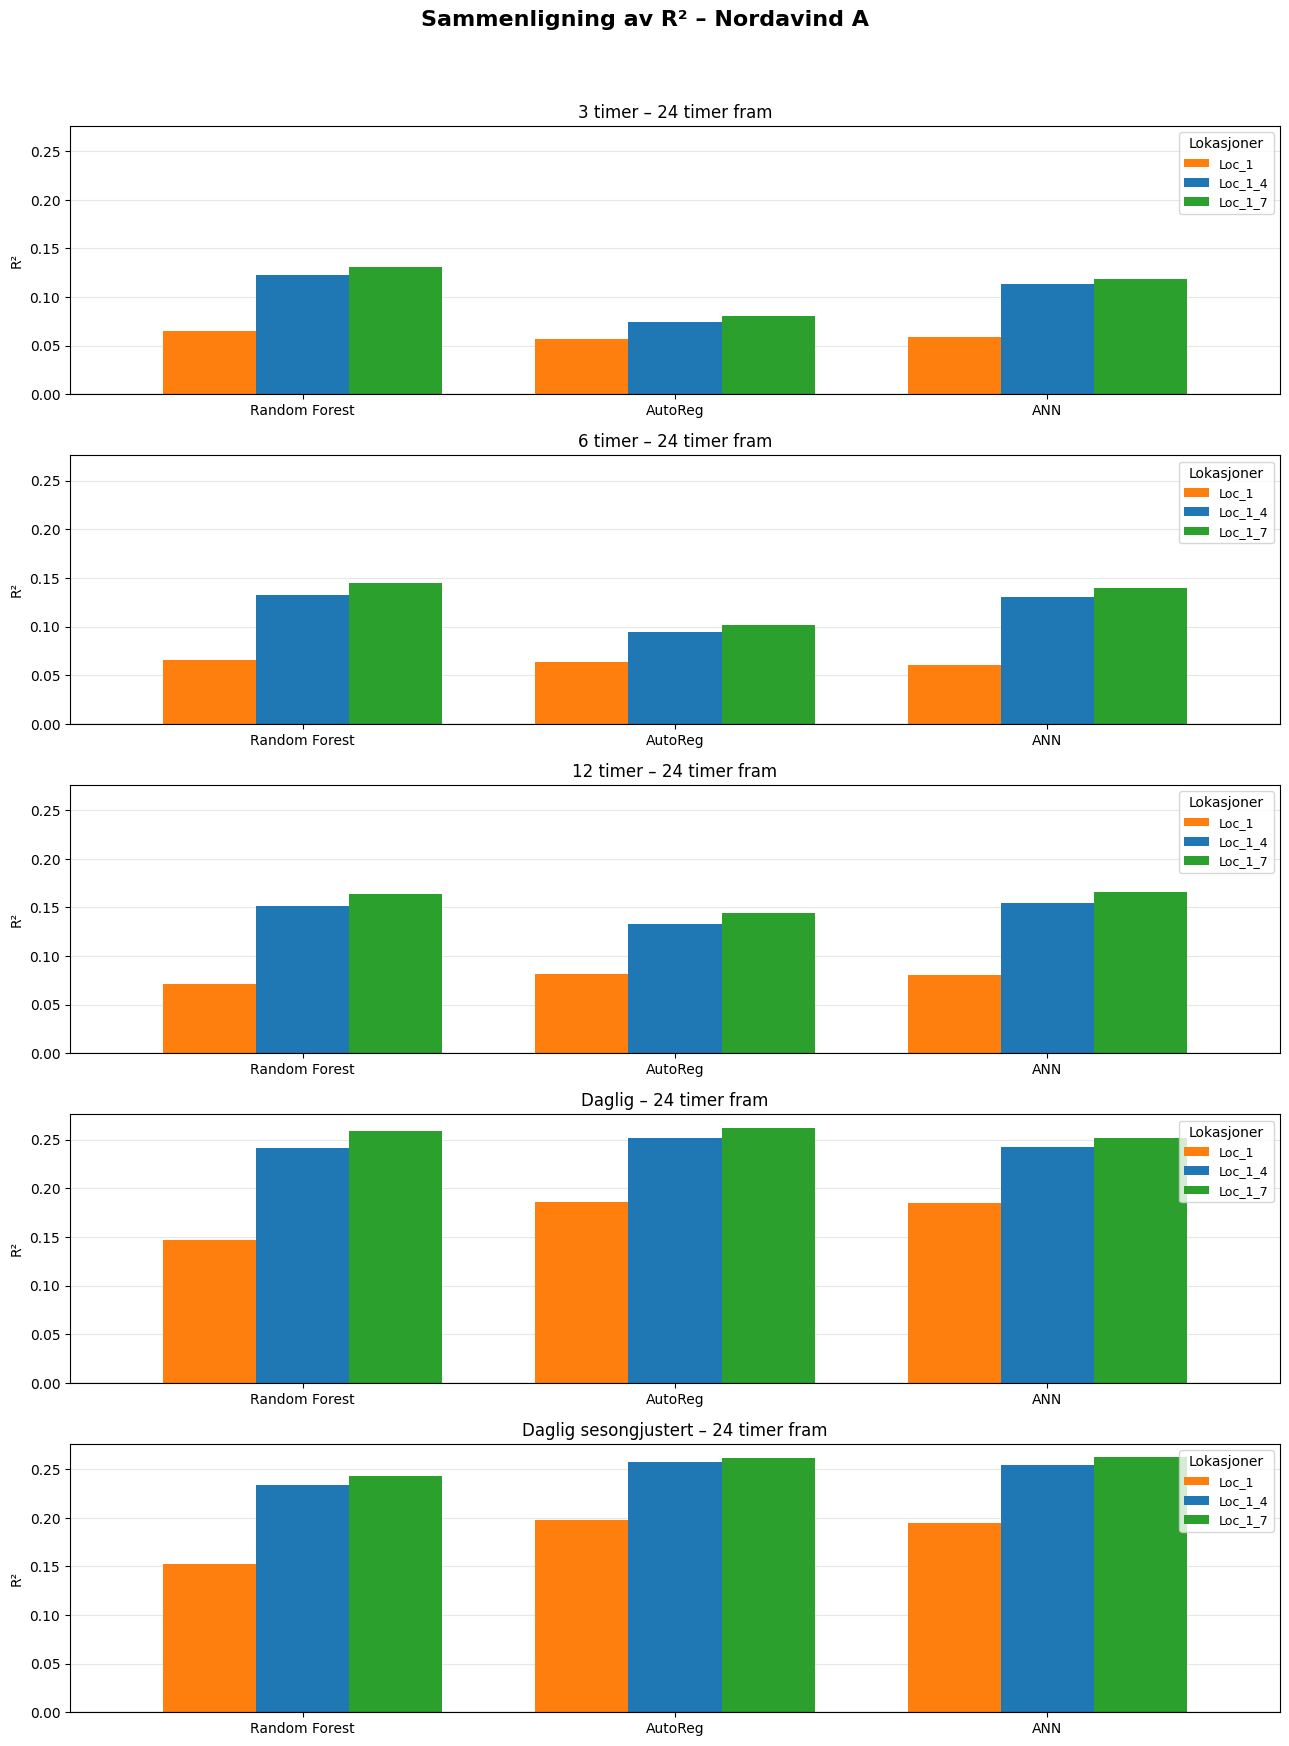

In [26]:

# Kun prediksjonsmodellene
models = ["Random Forest", "AutoReg", "ANN"]

# Modelloppsett
result_order = ["Loc_1", "Loc_1_4", "Loc_1_7"]

# Fjern benchmarkmodellene
results_filtered = results_comparison[
    results_comparison["Modell"].isin(models)
].copy()

# Rekkefølge på tidsoppløsningene
resolution_order = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

resolutions = [
    r for r in resolution_order
    if r in results_filtered["Tidsoppløsning"].values
]

# Farger for hvert modelloppsett
colors = {
    "Loc_1": "tab:orange",
    "Loc_1_4": "tab:blue",
    "Loc_1_7": "tab:green"
}

# Lag separate figurer for RMSE og R²
for metric in ["RMSE", "R²"]:

    fig, axes = plt.subplots(
        len(resolutions), 1,
        figsize=(13, 3.5 * len(resolutions)),
        sharey=True
    )

    axes = np.atleast_1d(axes)

    for ax, resolution in zip(axes, resolutions):

        subset = results_filtered[
            results_filtered["Tidsoppløsning"] == resolution
        ]

        # Lag tabell for stolpediagram
        table = subset.pivot_table(
            index="Modell",
            columns="Resultat",
            values=metric,
            aggfunc="first"
        )

        table = table.reindex(
            index=models,
            columns=result_order
        )

        # Stolpediagram
        table.plot(
            kind="bar",
            ax=ax,
            color=[colors[r] for r in result_order],
            width=0.75,
            rot=0
        )

        ax.set_title(
            f"{resolution} – 24 timer fram",
            fontsize=12
        )

        ax.set_ylabel(
            "RMSE (m/s)" if metric == "RMSE" else "R²"
        )

        ax.set_xlabel("")
        ax.grid(axis="y", alpha=0.3)
        ax.set_axisbelow(True)

        if metric == "R²":
            ax.axhline(
                0,
                color="black",
                linewidth=0.8
            )

        ax.legend(
            title="Lokasjoner",
            loc="upper right",
            fontsize=9
        )

    fig.suptitle(
        f"Sammenligning av {metric} – Nordavind A",
        fontsize=16,
        fontweight="bold",
        y=0.995
    )

    plt.tight_layout(rect=[0, 0, 1, 0.97])

    # Lagre figurene
    plt.savefig(
        f"Sammenligning_{metric}_lokasjoner.pdf",
        bbox_inches="tight",
        dpi=300
    )

    plt.show()

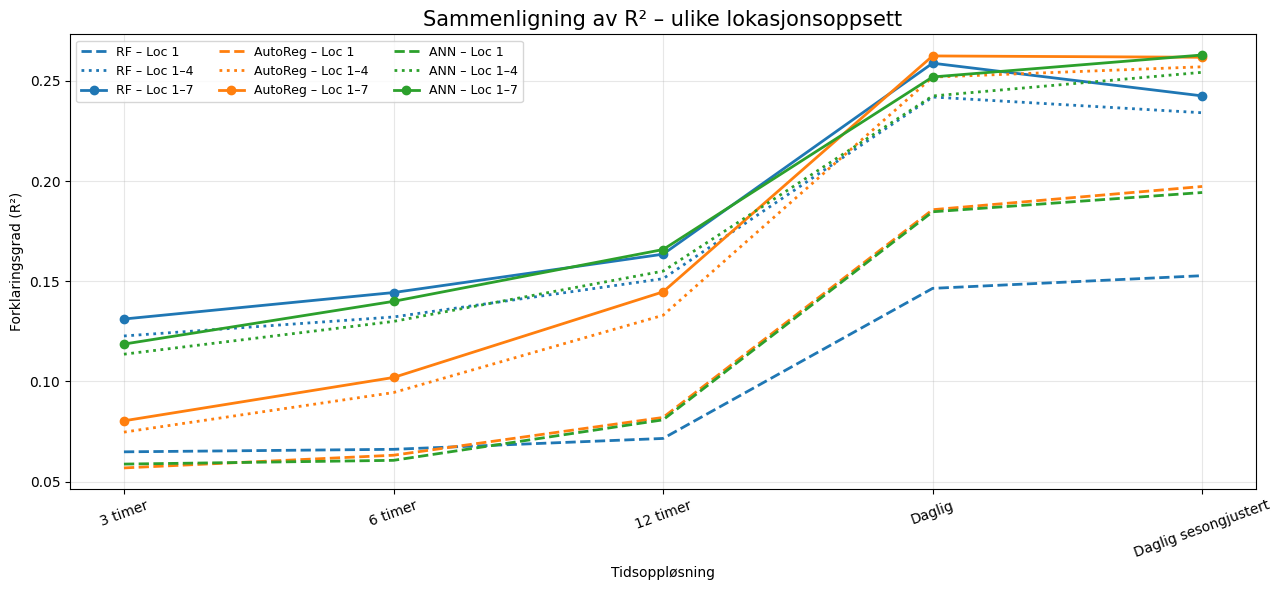

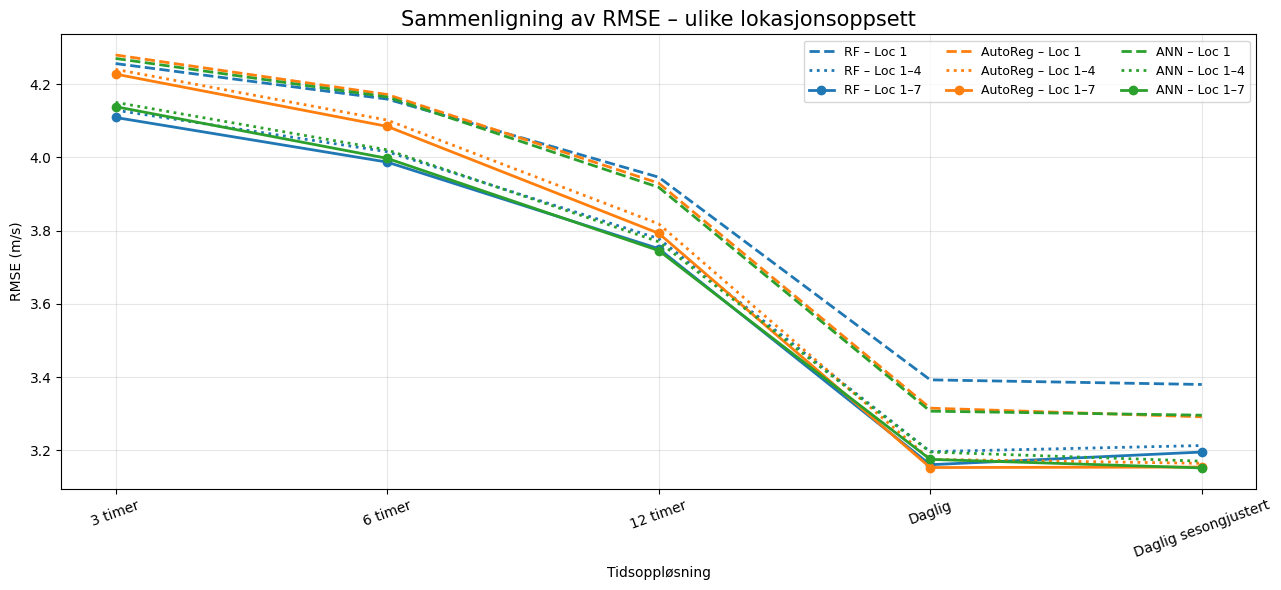

In [27]:

# Kun prediksjonsmodellene
models = ["Random Forest", "AutoReg", "ANN"]

# Tidsoppløsninger
resolution_order = [
    "3 timer",
    "6 timer",
    "12 timer",
    "Daglig",
    "Daglig sesongjustert"
]

# Modellfarger
colors = {
    "Random Forest": "tab:blue",
    "AutoReg": "tab:orange",
    "ANN": "tab:green"
}

# Navn i tegnforklaringen
model_labels = {
    "Random Forest": "RF",
    "AutoReg": "AutoReg",
    "ANN": "ANN"
}

# Linjestiler for lokasjonene
location_styles = {
    "Loc_1": {
        "linestyle": "--",
        "marker": None,
        "label": "Loc 1"
    },
    "Loc_1_4": {
        "linestyle": ":",
        "marker": None,
        "label": "Loc 1–4"
    },
    "Loc_1_7": {
        "linestyle": "-",
        "marker": "o",
        "label": "Loc 1–7"
    }
}

# Fjern benchmarkmodellene
results_filtered = results_comparison[
    results_comparison["Modell"].isin(models)
].copy()

# Lag én figur for R² og én for RMSE
for metric in ["R²", "RMSE"]:

    fig, ax = plt.subplots(figsize=(13, 6))

    for model in models:

        for location, style in location_styles.items():

            subset = results_filtered[
                (results_filtered["Modell"] == model) &
                (results_filtered["Resultat"] == location)
            ].copy()

            # Sorter etter tidsoppløsning
            subset["Tidsoppløsning"] = pd.Categorical(
                subset["Tidsoppløsning"],
                categories=resolution_order,
                ordered=True
            )

            subset = subset.sort_values("Tidsoppløsning")

            ax.plot(
                subset["Tidsoppløsning"].astype(str),
                subset[metric],
                label=f"{model_labels[model]} – {style['label']}",
                color=colors[model],
                linestyle=style["linestyle"],
                marker=style["marker"],
                linewidth=2,
                markersize=6
            )

    ax.set_title(
        f"Sammenligning av {metric} – ulike lokasjonsoppsett",
        fontsize=15
    )

    ax.set_xlabel("Tidsoppløsning")

    ax.set_ylabel(
        "Forklaringsgrad (R²)"
        if metric == "R²"
        else "RMSE (m/s)"
    )

    ax.grid(alpha=0.3)

    ax.legend(
        loc="best",
        ncol=3,
        fontsize=9
    )

    plt.xticks(rotation=20)
    plt.tight_layout()

    plt.savefig(
        f"Sammenligning_{metric}_linjeplot.pdf",
        bbox_inches="tight",
        dpi=300
    )

    plt.show()